Import the modules that will be used.

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

## Exercise 11.1

Determine by counting the number of mathematical operations the complexity of:

1. Dot product between two vectors
1. Matrix-vector product
1. Matrix-matrix product

for vectors of length $n$ and matrices of size $n \times n$.

This is a reasoning exercise - you do not need to write a program. Express your answers in text and using LaTeX in a Markdown cell.


### Optional

Test the complexity experimentally with your own functions for performing the operations, and
with the NumPy 'vectorised' equivalents.

## Exercise 11.2

For the recursive factorial algorithm in Activity 04, determine the algorithmic complexity by inspecting your implementation of the algorithm. Test this against numerical experiments.

### Solution

Recall the factorial algorithm from Activity 04.4:

In [5]:
def factorial(n):
    if n == 0:
        return 1
    else:
        return factorial(n - 1)*n

The function calls itself (recursively) $n$ times, hence it has complexity $O(n)$. We test this below and plot
the times.

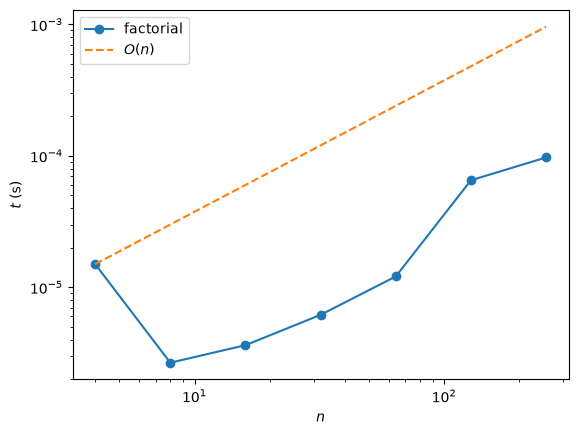

In [6]:
import time 

N = 2**np.arange(2, 9)
times = [] 

for n in N: 
    start = time.perf_counter()
    factorial(int(n)) 
    end = time.perf_counter()  
    times.append(end - start) 
plt.loglog(N, times, marker='o', label='factorial') 
plt.loglog(N, times[0] * N / N[0], '--', label='$O(n)$')  
plt.xlabel('$n$')  
plt.ylabel('$t$ (s)') 
plt.legend() 
plt.show()  

## Exercise 11.3

Determine experimentally the complexity of computing the determinant of a matrix. You can generate an $n \times n$ matrix using:

In [ ]:
n = 100
A = np.random.rand(n, n)

and the determinant can be computed by:

In [ ]:
det = np.linalg.slogdet(A)

Be sure that you test for sufficiently large $n$ to get into the 'large' $n$ regime.

### Solution

Time computation of determinant:

In [8]:
# Create array of problem sizes we want to test (powers of 2)
N = 2**np.arange(2, 12)
times=[]
for n in N:
    A=np.random.rand(n,n)
    t=%timeit -q -n1 -r1 -o np.linalg.slogdet(A)
    times.append(t.best)

Plot result:

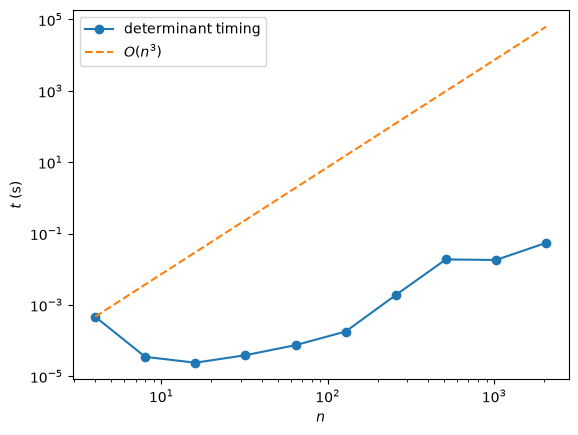

In [9]:
plt.loglog(N, times, marker='o', label='determinant timing')  
plt.loglog(N, times[0] * (N / N[0])**3, '--', label='$O(n^3)$') 
plt.xlabel('$n$') 
plt.ylabel('$t$ (s)')  
plt.legend() 
plt.show()  